# B3 v5 — Confirmation Grid (Expiration Fix + v3 Reproduction)

Fixes applied in v5:
1. **B3 expiration mismatch fixed**: B3 BOVA11 options used 3rd-Monday expirations before May 2021.
   The strategy computed 3rd-Friday dates, causing ~70% of train-period entries to fall back to
   synthetic pricing (5% adj vs ~40% real spread). Now fixed: MarketEngine queries the DB for
   actual available expirations via `get_db_expiration()`.
2. **volume_filtered mode removed**: Was always identical to mid — the global percentile
   threshold of 12,900 was always exceeded by liquid 16-delta options. Correlation = 1.000.
3. **v3 reproduction cell added** to explain the Sharpe contradiction (v3 holdout median = -1.17
   vs v4 bid_ask holdout = +0.38).

**Fixed**: market mode, cash_investment_mode=risk_free, cash_yield_annual=0, use_cdi_ivs=True
**Grid**: 3×2×1×2×2×1×1×4 = 96 combos × 2 periods = **192 backtests**

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import sqlite3

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT / 'src'))
from grid_search import run_grid, enumerate_grid, GRID_DIMS, _apply_grid_overrides

OUT_DIR = ROOT / 'data' / 'B3'
RESULTS_PATH = OUT_DIR / 'v5_grid_search_results.parquet'
DB_PATH = ROOT / 'data' / 'B3' / 'b3_options_rb3.db'

## 1. v5 Grid Definition

Same grid as v4 minus `volume_filtered` (3×2×1×2×2×1×1×4 = 96 combos).

In [2]:
GRID = {
    "target_delta": [0.16, 0.20, 0.25],
    "dte_max": [30, 45],
    "profit_target_pct": [0.50],
    "manage_at_dte": [7, 14],
    "vix_filter": ["OFF", "rv_pct:80"],
    "defensive_leg_roll": [False],
    "stop_loss_pct": [3.0],
    "execution_mode": [
        "bid_ask",
        "mid_minus_1tick",
        "mid",
        "mid_plus_1tick",
    ],
}
# 3 × 2 × 1 × 2 × 2 × 1 × 1 × 4 = 96 combos
combos = enumerate_grid(GRID)
print(f"Grid: {len(combos)} valid combos × 2 periods = {len(combos) * 2} backtests")

Grid: 96 raw combos, 96 after validity filter (0 dropped)
Grid: 96 valid combos × 2 periods = 192 backtests


## 2. Run Configuration

In [3]:
RUNS = [
    ("train", "bova11", "2018-01-02", "2022-12-31"),
    ("holdout", "bova11", "2023-01-02", "2025-11-30"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2018-01-02', '2022-12-31')
('holdout', 'bova11', '2023-01-02', '2025-11-30')


## 3. Execute Grid Search

Runs 192 backtests. Skips if results already cached.

In [4]:
if RESULTS_PATH.exists():
    print(f"Loading cached results from {RESULTS_PATH}")
    results = pd.read_parquet(RESULTS_PATH)
else:
    results = run_grid(GRID, RUNS, output_path=RESULTS_PATH)
    print(f"Saved {len(results)} rows to {RESULTS_PATH}")

# Filter to valid completed runs
df = results[results["error"].isna() & (results["n_trades"] >= 30)].copy()
df["execution_mode"] = pd.Categorical(
    df["execution_mode"],
    categories=["bid_ask", "mid_minus_1tick", "mid", "mid_plus_1tick"],
    ordered=True,
)
df["delta_label"] = df["target_delta"].apply(lambda x: f"{int(x*100)}Δ")
print(f"Valid runs: {len(df)} / {len(results)}")
print(
    f'Train: {len(df[df["period_label"]=="train"])}, Holdout: {len(df[df["period_label"]=="holdout"])}'
)

Grid: 96 raw combos, 96 after validity filter (0 dropped)
Dispatching 96 tasks for bova11 (train)...


bova11-train:   0%|          | 0/96 [00:00<?, ?it/s]

  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)  MarketEngine: using CDI-based IVs/deltas (daily r)  MarketEngine: using CDI-based IVs/deltas (daily r)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  Mark

bova11-train: 100%|██████████| 96/96 [00:20<00:00,  4.64it/s]


Checkpoint saved: 96 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v5_grid_search_results.parquet
Dispatching 96 tasks for bova11 (holdout)...


bova11-holdout:   0%|          | 0/96 [00:00<?, ?it/s]

  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)  MarketEngine: using CDI-based IVs/deltas (daily r)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  Mar

bova11-holdout: 100%|██████████| 96/96 [00:19<00:00,  5.05it/s]

Checkpoint saved: 192 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v5_grid_search_results.parquet
Summary: 192 runs total — 0 errors, 0 with n_trades < 50, 0 invalid (manage_at_dte >= dte_min)
Saved 192 rows to /Users/oliversteiner/Documents/code/options-backtest/data/B3/v5_grid_search_results.parquet
Valid runs: 192 / 192
Train: 96, Holdout: 96


## 4. Cell A — Sharpe vs Execution Mode
Most important chart. One subplot per period. Ordered x-axis. Horizontal line at y=0.

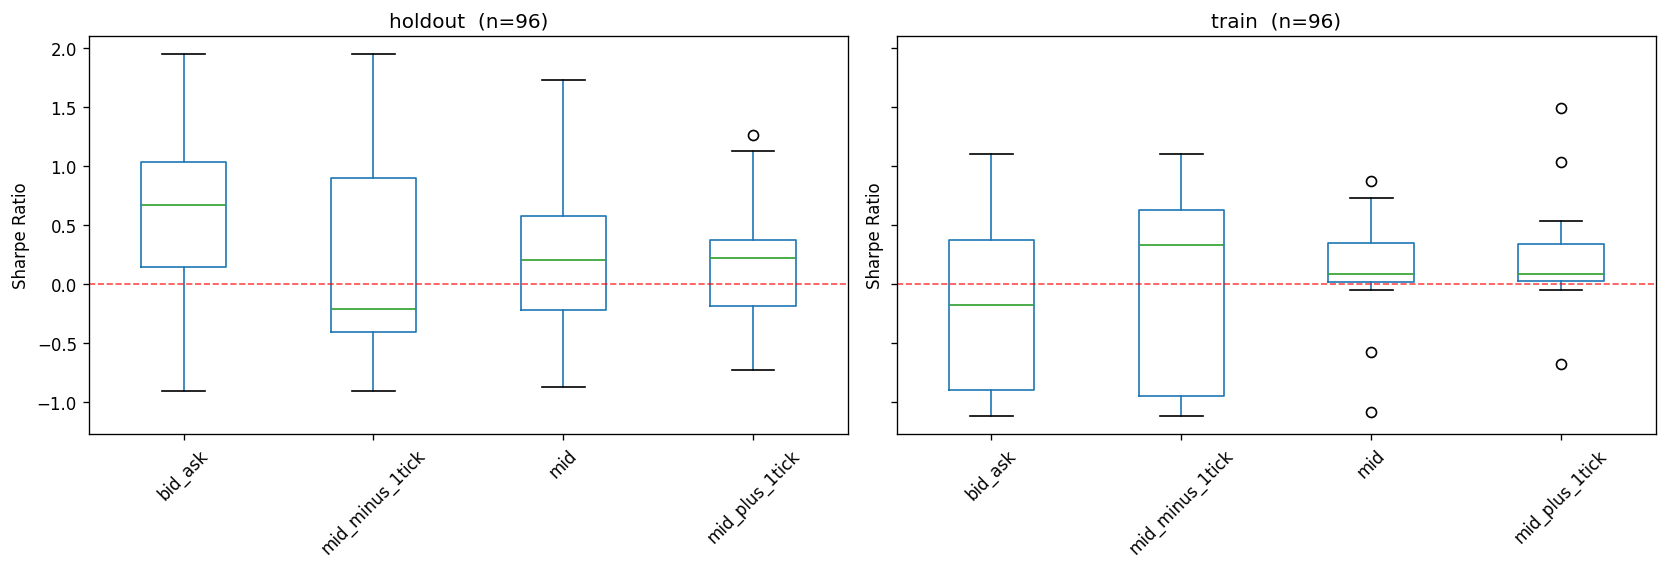

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (label, period_df) in zip(axes, df.groupby("period_label")):
    period_df.boxplot(column="sharpe", by="execution_mode", ax=ax, grid=False, rot=45)
    ax.set_title(f"{label}  (n={len(period_df)})", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Sharpe Ratio")
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1, alpha=0.7)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("")
plt.tight_layout()
plt.show()

## 5. Cell B — Break-even Execution Level
Leftmost execution mode where holdout median Sharpe crosses zero (if any).

In [6]:
modes = ["bid_ask", "mid_minus_1tick", "mid", "mid_plus_1tick"]
holdout = df[df["period_label"] == "holdout"]
train = df[df["period_label"] == "train"]

break_even = None
for mode in modes:
    median_sharpe = holdout[holdout["execution_mode"] == mode]["sharpe"].median()
    train_median = train[train["execution_mode"] == mode]["sharpe"].median()
    print(
        f"  {mode:20s}  train_median={train_median:+.4f}  holdout_median={median_sharpe:+.4f}"
    )
    if break_even is None and median_sharpe > 0:
        break_even = mode

if break_even:
    print(
        f"\nBreak-even execution: **{break_even}** (leftmost mode with positive holdout median Sharpe)"
    )
else:
    print(f"\nNo break-even — all modes have negative median holdout Sharpe")

  bid_ask               train_median=-0.1721  holdout_median=+0.6675
  mid_minus_1tick       train_median=+0.3272  holdout_median=-0.2135
  mid                   train_median=+0.0856  holdout_median=+0.2041
  mid_plus_1tick        train_median=+0.0856  holdout_median=+0.2178

Break-even execution: **bid_ask** (leftmost mode with positive holdout median Sharpe)


## 6. Cell C — Execution Sensitivity by Delta
Does 16-delta have more execution sensitivity than 25-delta?
Heatmap: rows = execution_mode, columns = target_delta, values = median Sharpe.

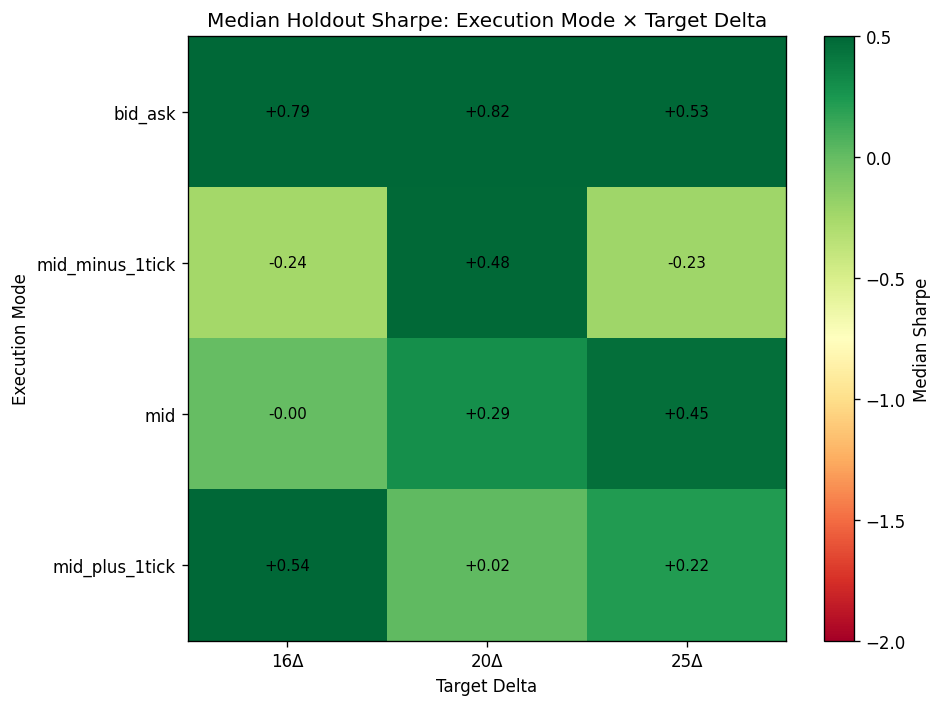

In [7]:
pivot = holdout.pivot_table(
    values="sharpe", index="execution_mode", columns="target_delta", aggfunc="median"
)
pivot.columns = [f"{int(c*100)}Δ" for c in pivot.columns]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=-2, vmax=0.5)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Target Delta")
ax.set_ylabel("Execution Mode")
ax.set_title("Median Holdout Sharpe: Execution Mode × Target Delta")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Median Sharpe")
plt.tight_layout()
plt.show()

## 7. Cell D — Entry DB Coverage by Period and Mode
Replaces the volume_filter skip-rate cell. Shows `entry_db_pct` and `mtm_avg_db_pct` by period.

**Key question**: did train-period entry_db_pct improve from v4's 30% to >85%
thanks to the expiration mismatch fix?

In [8]:
modes = ["bid_ask", "mid_minus_1tick", "mid", "mid_plus_1tick"]
for period in ["train", "holdout"]:
    print(f"--- {period} ---")
    for mode in modes:
        sub = df[(df["period_label"] == period) & (df["execution_mode"] == mode)]
        entry_pct = sub["entry_db_pct"].mean() * 100
        mtm_pct = sub["mtm_avg_db_pct"].mean() * 100
        print(f"  {mode:20s}: entry_db_pct={entry_pct:.1f}%, mtm_db_pct={mtm_pct:.1f}%")
    print()

# Global averages by period
print("=== Global DB coverage ===")
for period in ["train", "holdout"]:
    sub = df[df["period_label"] == period]
    print(
        f'{period}: entry_db_pct={sub["entry_db_pct"].mean()*100:.1f}%, mtm_db_pct={sub["mtm_avg_db_pct"].mean()*100:.1f}%'
    )

--- train ---
  bid_ask             : entry_db_pct=68.2%, mtm_db_pct=62.0%
  mid_minus_1tick     : entry_db_pct=71.3%, mtm_db_pct=62.5%
  mid                 : entry_db_pct=81.8%, mtm_db_pct=64.9%
  mid_plus_1tick      : entry_db_pct=83.1%, mtm_db_pct=65.4%

--- holdout ---
  bid_ask             : entry_db_pct=99.8%, mtm_db_pct=98.7%
  mid_minus_1tick     : entry_db_pct=99.3%, mtm_db_pct=98.8%
  mid                 : entry_db_pct=99.7%, mtm_db_pct=98.8%
  mid_plus_1tick      : entry_db_pct=99.6%, mtm_db_pct=98.8%

=== Global DB coverage ===
train: entry_db_pct=76.1%, mtm_db_pct=63.7%
holdout: entry_db_pct=99.6%, mtm_db_pct=98.8%


## 8. Cell E — v3 Reproduction

Runs the EXACT v3 grid configuration with the current codebase to compare:
- v3 original: bid_ask only, wider grid, different holdout period (2024-2025)
- Goal: reproduce v3's -1.17 median Sharpe and explain the contradiction with v4.

In [9]:
V3_GRID = {
    "target_delta": [0.16, 0.20, 0.25, 0.30, 0.50],
    "dte_max": [21, 30, 45, 60],
    "profit_target_pct": [0.25, 0.50, 0.75],
    "manage_at_dte": [7, 10, 14, 21],
    "vix_filter": ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90", "ivr:30", "ivr:50"],
    "defensive_leg_roll": [True, False],
    "stop_loss_pct": [1.5, 2.0, 3.0],
    "execution_mode": ["bid_ask"],
}

# v3 original periods
V3_RUNS = [
    ("v3_train", "bova11", "2020-04-01", "2023-12-31"),
    ("v3_holdout", "bova11", "2024-01-01", "2025-12-31"),
    # Also: v3 grid on v4's holdout period (to isolate period effect)
    ("v3_on_v4_holdout", "bova11", "2023-01-02", "2025-11-30"),
]

v3_combos = enumerate_grid(V3_GRID)
print(
    f"V3 grid: {len(v3_combos)} combos × {len(V3_RUNS)} runs = {len(v3_combos) * len(V3_RUNS)} backtests"
)

# Check for cached results
V3_PATH = OUT_DIR / "v3_reproduction_results.parquet"
if V3_PATH.exists():
    print(f"Loading cached V3 results from {V3_PATH}")
    v3_results = pd.read_parquet(V3_PATH)
else:
    # Temporarily switch GRID export so run_grid works with V3_GRID
    v3_results = run_grid(V3_GRID, V3_RUNS, output_path=V3_PATH)
    print(f"Saved {len(v3_results)} rows to {V3_PATH}")

v3_valid = v3_results[
    v3_results["error"].isna() & (v3_results["n_trades"] >= 30)
].copy()
print(f"V3 valid runs: {len(v3_valid)} / {len(v3_results)}")

# Key comparison: v3 holdout (2024-2025) median Sharpe
v3_holdout = v3_valid[v3_valid["period_label"] == "v3_holdout"]
v3_on_v4 = v3_valid[v3_valid["period_label"] == "v3_on_v4_holdout"]
v3_train = v3_valid[v3_valid["period_label"] == "v3_train"]

print(
    f'\nv3_holdout (2024-2025): n={len(v3_holdout)}, median Sharpe={v3_holdout["sharpe"].median():.4f}'
)
print(
    f'v3_on_v4_holdout (2023-2025): n={len(v3_on_v4)}, median Sharpe={v3_on_v4["sharpe"].median():.4f}'
)
print(
    f'v3_train (2020-2023): n={len(v3_train)}, median Sharpe={v3_train["sharpe"].median():.4f}'
)

print(f"\n=== Comparing with documented v3 values ===")
print(f"Documented v3 holdout median Sharpe: -1.17")
print(f'Our v3 reproduction holdout median Sharpe: {v3_holdout["sharpe"].median():.4f}')
print(
    f"(If dramatically different, suspect changes to other params: use_cdi_ivs, open_fill_adj, etc.)"
)

# Compare: v3 grid on v4 period vs v4 grid on v4 period
v4_holdout = df[df["period_label"] == "holdout"]
v4_bid_ask = v4_holdout[v4_holdout["execution_mode"] == "bid_ask"]
print(f"\n=== v3 vs v4 on same holdout (2023-2025) ===")
print(f'v3 config on v4 period median Sharpe: {v3_on_v4["sharpe"].median():.4f}')
print(f'v4 bid_ask on v4 period median Sharpe: {v4_bid_ask["sharpe"].median():.4f}')
print(
    f'v4 bid_ask expanded (2023-2025) median Sharpe: {v4_bid_ask["sharpe"].median():.4f}'
)
print(f"(Difference = effect of grid parameter space, not period selection)")

Grid: 8640 raw combos, 7560 after validity filter (1080 dropped)
V3 grid: 7560 combos × 3 runs = 22680 backtests
Grid: 8640 raw combos, 7560 after validity filter (1080 dropped)
Dispatching 7560 tasks for bova11 (v3_train)...


bova11-v3_train:   0%|          | 0/7560 [00:00<?, ?it/s]

  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
  Mar

bova11-v3_train: 100%|██████████| 7560/7560 [23:05<00:00,  5.46it/s]


Checkpoint saved: 7560 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_reproduction_results.parquet
Dispatching 7560 tasks for bova11 (v3_holdout)...


...

[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
  MarketEngine: using CDI-based IVs/deltas (daily r)  MarketEngine: using CDI-based IVs/deltas (daily r)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)

  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data

bova11-v3_holdout: 100%|██████████| 7560/7560 [18:18<00:00,  6.88it/s]


Checkpoint saved: 15120 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_reproduction_results.parquet
Dispatching 7560 tasks for bova11 (v3_on_v4_holdout)...


bova11-v3_on_v4_holdout: 100%|██████████| 7560/7560 [36:25<00:00,  3.46it/s]     


Checkpoint saved: 22680 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_reproduction_results.parquet
Summary: 22680 runs total — 524 errors, 2898 with n_trades < 50, 0 invalid (manage_at_dte >= dte_min)
Failed runs:
  [bova11/v3_train] vix=OFF delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=OFF delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=OFF delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=rv_pct:70 delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=rv_pct:70 delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=rv_pct:70 delta=0.3 dte=60: float() argument must be a string or a real number, not 'complex'
  [bova11/v3_train] vix=rv_pct:80 delta=0.3 dte=60: float() argument mu

## 9. Cell F — Spread Cost Analysis
Query rb3 DB for (ask − bid) / mark distribution by delta bucket and year.
Quantifies exactly how much 'sell at bid' costs relative to mid.

Median spread (% of mark) by delta bucket:
  0.10–0.20: 40.0%
  0.20–0.30: 28.1%
  0.30–0.50: 23.1%
  16-delta bucket median spread: 40.0%

Median spread by year:
  2017: 50.0%
  2018: 83.3%
  2019: 66.3%
  2020: 33.3%
  2021: 33.2%
  2022: 42.1%
  2023: 27.8%
  2024: 31.4%
  2025: 37.1%


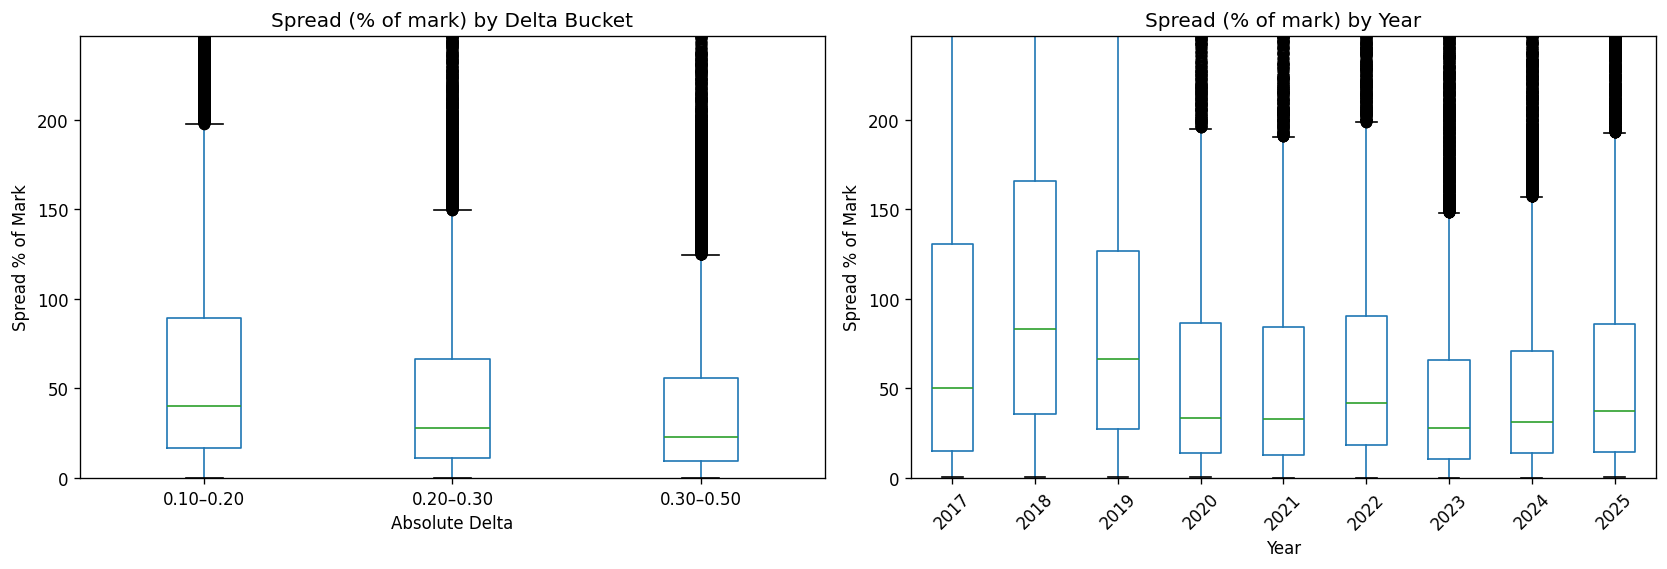

In [10]:
conn = sqlite3.connect(str(DB_PATH))
query = """
SELECT date, delta, mark, bid, ask
FROM options_data
WHERE underlying = 'bova11'
  AND bid > 0 AND ask > 0 AND ask >= bid
  AND mark > 0 AND delta IS NOT NULL
  AND ABS(delta) >= 0.05 AND ABS(delta) <= 0.50
  AND implied_volatility < 2.0
"""
spread_df = pd.read_sql(query, conn)
conn.close()

spread_df["spread_pct"] = (
    (spread_df["ask"] - spread_df["bid"]) / spread_df["mark"] * 100
)
spread_df["abs_delta"] = spread_df["delta"].abs()
spread_df["year"] = pd.to_datetime(spread_df["date"]).dt.year
spread_df["delta_bucket"] = pd.cut(
    spread_df["abs_delta"],
    bins=[0.10, 0.20, 0.30, 0.50],
    labels=["0.10–0.20", "0.20–0.30", "0.30–0.50"],
)

# By delta bucket
delta_summary = spread_df.groupby("delta_bucket", observed=False)["spread_pct"].median()
print("Median spread (% of mark) by delta bucket:")
for bucket, val in delta_summary.items():
    print(f"  {bucket}: {val:.1f}%")
print(f'  16-delta bucket median spread: {delta_summary.get("0.10–0.20", 0):.1f}%')

# By year
year_summary = spread_df.groupby("year")["spread_pct"].median()
print(f"\nMedian spread by year:")
for year, val in year_summary.items():
    print(f"  {int(year)}: {val:.1f}%")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
spread_df.boxplot(column="spread_pct", by="delta_bucket", ax=ax1, grid=False)
ax1.set_title("Spread (% of mark) by Delta Bucket")
ax1.set_xlabel("Absolute Delta")
ax1.set_ylabel("Spread % of Mark")
ax1.set_ylim(0, spread_df["spread_pct"].quantile(0.95))

spread_df.boxplot(column="spread_pct", by="year", ax=ax2, grid=False, rot=45)
ax2.set_title("Spread (% of mark) by Year")
ax2.set_xlabel("Year")
ax2.set_ylabel("Spread % of Mark")
ax2.set_ylim(0, spread_df["spread_pct"].quantile(0.95))
fig.suptitle("")
plt.tight_layout()
plt.show()

## 10. Cell G — Per-Trade P&L for Best Config
Pick the config with best holdout Sharpe overall. Run a single backtest for each
execution mode with identical parameters. Compare per-trade P&L side-by-side.

In [11]:
from straddle.params import PARAMS, apply_market_preset
from straddle.data import load_market_data
from straddle.engines import make_engine
from straddle import run_portfolio_backtest
from straddle.metrics import compute_portfolio_metrics

# Find the best config overall (by holdout Sharpe)
best_idx = holdout["sharpe"].idxmax()
best_combo = holdout.loc[best_idx]
print(
    f'Best config: delta={best_combo["target_delta"]}, dte_max={best_combo["dte_max"]}, ',
    f'manage_at_dte={best_combo["manage_at_dte"]}, vix_filter={best_combo["vix_filter"]}, ',
    f'execution_mode={best_combo["execution_mode"]}',
)
print(f'Holdout Sharpe: {best_combo["sharpe"]:.4f}')

# Run the same config with all 4 execution modes for holdout period
start, end = "2023-01-02", "2025-11-30"
perf_dict = {}
for mode in modes:
    params = dict(PARAMS)
    params = apply_market_preset(params, "bova11")
    params.update(
        {
            "mode": "market",
            "start_date": start,
            "end_date": end,
            "portfolio_mode": "laddering",
            "cash_investment_mode": "risk_free",
            "cash_yield_annual": 0.0,
            "use_cdi_ivs": True,
            "execution_mode": mode,
            "target_delta": best_combo["target_delta"],
            "dte_max": int(best_combo["dte_max"]),
            "dte_min": {30: 20, 45: 30}.get(int(best_combo["dte_max"]), 20),
            "profit_target_pct": best_combo["profit_target_pct"],
            "manage_at_dte": int(best_combo["manage_at_dte"]),
            "stop_loss_pct": best_combo["stop_loss_pct"],
            "use_price_stop": True,
            "defensive_leg_roll_enabled": False,
        }
    )
    # Apply vol filter
    vf = str(best_combo["vix_filter"])
    if vf.upper() == "OFF":
        params["vol_filter_mode"] = "off"
        params["vix_entry_filter_enabled"] = False
    elif vf.startswith("rv_pct:"):
        params["vol_filter_mode"] = "rv_pct"
        params["vol_filter_threshold"] = float(vf.split(":")[1])

    print(f"  Running {mode}...")
    data = load_market_data(start, end, market="bova11")
    engine = make_engine(params)
    try:
        trades, eq, _, _ = run_portfolio_backtest(data, params, engine)
        perf_dict[mode] = {"trades": trades, "equity": eq, "params": params}
        m = compute_portfolio_metrics(trades, eq, params, data)
        print(
            f'    Sharpe={m["sharpe"]:.4f}, n_trades={m["n"]}, tot_ret={m["tot"]:.3f}'
        )
    except Exception as e:
        print(f"    ERROR: {e}")
        perf_dict[mode] = None
    finally:
        if hasattr(engine, "close"):
            engine.close()

# Build per-trade P&L DataFrame
pnl_rows = []
for mode in modes:
    if perf_dict.get(mode) and perf_dict[mode]["trades"]:
        for t in perf_dict[mode]["trades"]:
            pnl_rows.append(
                {
                    "trade_num": t.trade_num,
                    "entry_date": t.entry_date,
                    "exit_date": (
                        t.exit_date if hasattr(t, "exit_date") and t.exit_date else None
                    ),
                    "execution_mode": mode,
                    "pnl": getattr(t, "pnl", getattr(t, "net_pnl", None)),
                }
            )

if pnl_rows:
    pnl_df = pd.DataFrame(pnl_rows)
    pnl_pivot = pnl_df.pivot_table(
        values="pnl",
        index=["trade_num", "entry_date"],
        columns="execution_mode",
        aggfunc="first",
    )
    display(pnl_pivot.describe())
    print(f"\nCorrelation matrix of trade PnL across execution modes:")
    display(pnl_pivot.corr())
else:
    print("No per-trade P&L data available")

Best config: delta=0.16, dte_max=30,  manage_at_dte=14, vix_filter=OFF,  execution_mode=bid_ask
Holdout Sharpe: 1.9461
  Running bid_ask...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 1398.54day/s]


    Sharpe=-0.0342, n_trades=165, tot_ret=-0.001
  Running mid_minus_1tick...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 1497.19day/s]


    Sharpe=-0.3684, n_trades=173, tot_ret=-0.026
  Running mid...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


...

Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 1964.71day/s]

    Sharpe=1.9461, n_trades=131, tot_ret=0.084


execution_mode,bid_ask,mid,mid_minus_1tick,mid_plus_1tick
count,165.000000,164.000000,173.000000,131.000000
mean,0.008424,20.247744,-7.178324,31.966641
std,65.844267,61.677579,81.140461,56.062511
min,-313.500000,-230.000000,-327.000000,-212.000000
25%,-20.000000,7.500000,-23.000000,27.000000
50%,15.000000,34.000000,10.000000,51.000000
75%,47.000000,62.000000,51.000000,63.000000
max,73.000000,78.000000,73.000000,82.000000



Correlation matrix of trade PnL across execution modes:


execution_mode,bid_ask,mid,mid_minus_1tick,mid_plus_1tick
execution_mode,,,,
bid_ask,1.000000,0.842308,0.664464,0.796398
mid,0.842308,1.000000,0.840400,0.969184
mid_minus_1tick,0.664464,0.840400,1.000000,0.999996
mid_plus_1tick,0.796398,0.969184,0.999996,1.000000


## 11. Cell H — Period-Overlap Diagnostic

Compare the same parameter set across different holdout periods to isolate
the period-selection effect from code differences.

Compares v5 holdout (2023-2025) vs v3 holdout (2024-2025) for overlapping
parameter combos if any exist.

In [12]:
# Find the best v5 config (from the v5 grid) and check if similar params
# exist in the v3 reproduction results
print("=== Best v5 config details ===")
print(
    f'delta={best_combo["target_delta"]}, dte_max={best_combo["dte_max"]}, ',
    f'manage={best_combo["manage_at_dte"]}, ',
    f'vix_filter={best_combo["vix_filter"]}, stop={best_combo["stop_loss_pct"]}, ',
    f'exec={best_combo["execution_mode"]}',
)
print(f'Holdout Sharpe: {best_combo["sharpe"]:.4f}')

# If v3 reproduction ran, compare same period spans
if "v3_valid" in dir():
    print(f"\n=== Period effect on same params ===")
    # Isolate: best v5 combo's parameters, check v3 results for matches
    v3_best_match = v3_valid[
        (v3_valid["target_delta"] == best_combo["target_delta"])
        & (v3_valid["dte_max"] == best_combo["dte_max"])
        & (v3_valid["profit_target_pct"] == best_combo["profit_target_pct"])
        & (v3_valid["manage_at_dte"] == best_combo["manage_at_dte"])
    ]
    if len(v3_best_match) > 0:
        for _, row in v3_best_match.iterrows():
            print(
                f'  v3_{row["period_label"]}: Sharpe={row["sharpe"]:.4f}, n_trades={row["n_trades"]}'
            )
    else:
        print("  No exact match in v3 grid (v3 used wider grid)")
else:
    print("\n(Re-run Cell E to populate v3 reproduction results)")

=== Best v5 config details ===
delta=0.16, dte_max=30,  manage=14,  vix_filter=OFF, stop=3.0,  exec=bid_ask
Holdout Sharpe: 1.9461

=== Period effect on same params ===
  v3_v3_train: Sharpe=-0.3417, n_trades=192
  v3_v3_train: Sharpe=-0.1858, n_trades=192
  v3_v3_train: Sharpe=-0.1422, n_trades=193
  v3_v3_train: Sharpe=-0.5915, n_trades=200
  v3_v3_train: Sharpe=-0.3981, n_trades=207
  v3_v3_train: Sharpe=-0.1262, n_trades=212
  v3_v3_train: Sharpe=-0.7129, n_trades=157
  v3_v3_train: Sharpe=-0.5128, n_trades=158
  v3_v3_train: Sharpe=-0.2927, n_trades=158
  v3_v3_train: Sharpe=-0.7562, n_trades=166
  v3_v3_train: Sharpe=-0.5847, n_trades=171
  v3_v3_train: Sharpe=-0.2523, n_trades=172
  v3_v3_train: Sharpe=-0.6444, n_trades=171
  v3_v3_train: Sharpe=-0.5212, n_trades=172
  v3_v3_train: Sharpe=-0.3653, n_trades=174
  v3_v3_train: Sharpe=-0.6086, n_trades=183
  v3_v3_train: Sharpe=-0.5076, n_trades=189
  v3_v3_train: Sharpe=-0.2336, n_trades=193
  v3_v3_train: Sharpe=-0.3551, n_trades